In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange
from scipy.special import jv

#### References: 
- [1] ITER Physics Basis Editors et al. 1999 Nucl. Fusion 39 2137
- [2] Progress in the ITER Physics Basis 2007 Nucl. Fusion 47 S1–S413
- [3] Luce, T. C., et al. (2018). "Assessment of the baseline scenario at q₉₅ ~ 3 for ITER". Nuclear Fusion, 58(12), 126021. 


### geometry

In [2]:
params = {
    "q0": 1.0,         # Safety factor sull'asse magnetico (limitato da instabilità sawtooth)
    "q95": 3.0,        # Safety factor al 95% del flusso magnetico (limite di stabilità)
    "q_edge": 4.1,     # Valore teorico alla separatrice (separatrix, rho = 1.0)
    "alpha": 3.5,      # Esponente di profilo (forma geometrica della corrente ITPA)
    "beta": 1.2,       # Fattore di correzione per il gradiente di bordo (edge shear)
    "R0": 6.20,       # Raggio maggiore dell'asse del plasma (metri)
    "a": 2.00,        # Raggio minore del plasma (metri)
    "B0": 5.30,       # Campo toroidale nominale all'asse del plasma (Tesla)
}

# q-factor (twist of magnetic field lines)

$$
q = (\frac{\text{toroidal turns}}{\text{poloidal turns}})_\text{along B-lines}\\
q(r) = q_0 + (q_\text{edge}-q_0)\left( \frac{r}{a} \right)^\alpha - \delta q \\
\delta q(r) = \text{edge correction} = \beta \left( \frac{r}{a}\right)^8 \left(1- \frac{r}{a} \right)

$$

In [3]:
def q(rho, p):
    """
    Calcola il profilo del safety factor q in funzione del raggio normalizzato rho.
    Utilizza la formulazione ITPA generalizzata per plasmi allungati e triangolari.
    """
    # Profilo base a potenza
    q_base = p["q0"] + (p["q_edge"] - p["q0"]) * (rho ** p["alpha"])
    
    # Correzione di bordo per simulare l'effetto dell'elevato shear magnetico a rho > 0.8
    # tipico della configurazione a X-point di ITER
    correzione_bordo = p["beta"] * (rho ** 8) * (1 - rho)
    
    return q_base - correzione_bordo

qITER = lambda rho: q(rho, params)

### radial grid

In [4]:
dx = 0.01     
x = np.arange(0.01, 1, dx)

# Magnetic field

$$
B_t(\vec{r}) = B_0 \frac{R_0}{R(\vec{r})} =  B_0 \frac{R_0}{R_0 + r\cos{\theta}} \\
B_p(\vec{r}) = \frac{r}{R_0}\frac{B_t(\vec{r})}{q(r)} = \frac{B_0}{q(r)} \frac{r}{R_0 + r\cos{\theta}}
$$

In [5]:
def BT(rho, theta, p):
    """
    Calcola l'andamento del campo magnetico toroidale in funzione del raggio maggiore R.
    Il campo decresce come 1/R muovendosi dall'interno verso l'esterno.
    """
    return p["B0"] * p["R0"] / (p["R0"] + p["a"] * np.cos(theta) * rho)

BT_ITER = lambda rho, theta: BT(rho, theta, params)
BP_ITER = lambda rho, theta: rho*params["a"] * BT_ITER(rho, theta) /( params["R0"] * qITER(rho))

# magnetic configuration

Text(0.5, 0.98, 'Magnetic configuration')

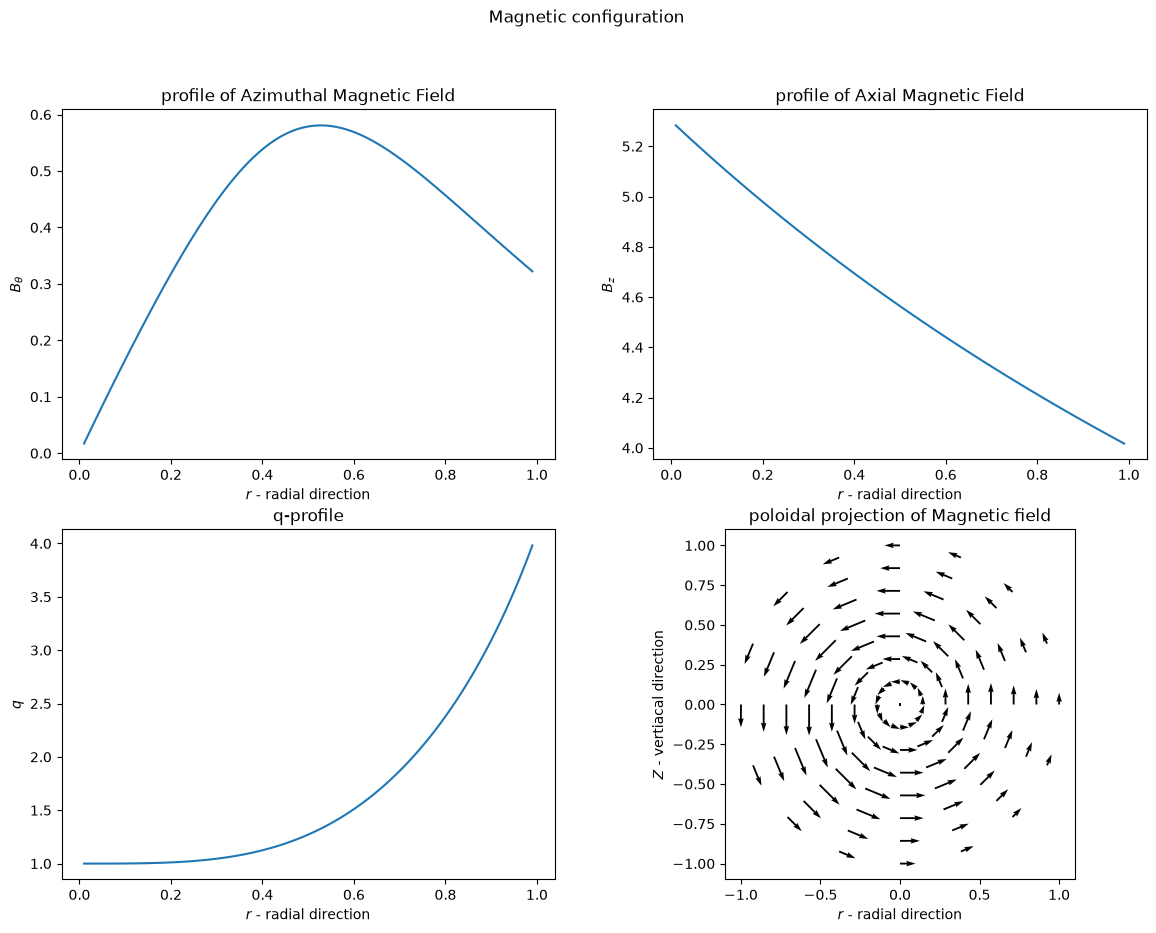

In [6]:
fig, ax = plt.subplots(2,2, figsize=(14,10))

ax[0,0].plot(x, BP_ITER(x, 0))
ax[0,0].set_xlabel('$r$ - radial direction')
ax[0,0].set_ylabel('$B_{\\theta}$')
ax[0,0].set_title('profile of Azimuthal Magnetic Field')



ax[0,1].plot(x, BT_ITER(x, 0))
ax[0,1].set_xlabel('$r$ - radial direction')
ax[0,1].set_ylabel('$B_z$')
ax[0,1].set_title('profile of Axial Magnetic Field')

ax[1,0].plot(x, qITER(x))
ax[1,0].set_xlabel('$r$ - radial direction')
ax[1,0].set_ylabel('$q$')
ax[1,0].set_title('q-profile')

theta = np.linspace(0, 2*np.pi, 17)[:-1]
r = np.linspace(0,1,8)

R, TH = np.meshgrid(r,theta)

X = R*np.cos(TH)
Y = R*np.sin(TH)

Bth = BP_ITER(R, TH)
U = -np.sin(TH)*Bth
V =  np.cos(TH)*Bth

ax[1,1].quiver(X,Y,U,V)
ax[1,1].set_xlabel('$r$ - radial direction')
ax[1,1].set_ylabel('$Z$ - vertiacal direction')
ax[1,1].set_aspect('equal')
ax[1,1].set_title('poloidal projection of Magnetic field')
fig.suptitle('Magnetic configuration')

# The magnetic field lines ... to be continued ...

c:\Users\Utente\Projects\Marseille\.venv\Lib\site-packages\matplotlib\patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


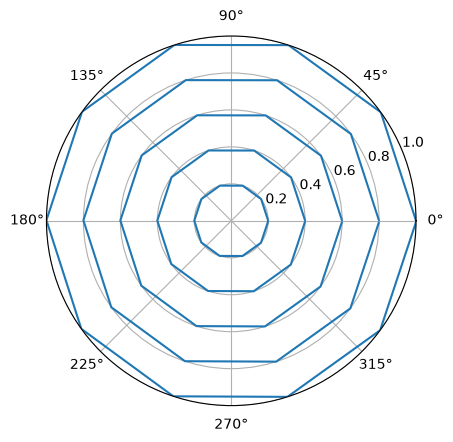

In [11]:
theta = np.linspace(0, 2*np.pi, 1000)[:-1]
r = np.linspace(0,1,100)

R, TH = np.meshgrid(theta,r)

X = R*np.cos(TH)
Y = R*np.sin(TH)

Bth = BT_ITER(R, TH)
U = -np.sin(TH)*Bth
V =  np.cos(TH)*Bth

ax = plt.subplot(polar=True)
ax.streamplot(theta, r, Bth, np.zeros(Bth.shape), arrowsize=0, density=.2 )


# Resonant surfaces
- radial surfaces $r_0$ where the magnetic field lines close on them self ($\imply$q is rational).
$$
 q(r_0 ) = \frac{m}{n}
$$
- some of the typical values are $1/1$, $3/2$, $2/1$, $3/1$, $4/1$

In [15]:
def Newton_root(f, guess, tol, max_iter):
    q = guess
    for i in range(max_iter):
        f_q = f(q)
        f_prime_q = (f(q + tol) - f(q - tol)) / (2*tol)  # Numerical derivative
        if abs(f_prime_q) < tol:
            # if the derivative is small, we are close to a stationary point
            # Let's find the max/min and see if it is a root (or close enought to it)
            f_prime = lambda q: (f(q + tol) - f(q - tol)) / (2*tol)
            q_new = Newton_root(f_prime, q, tol=tol, max_iter=max_iter)
            if abs(q_new - q) < tol:
                if abs(f(q_new)) < tol:
                    return q_new
                else:
                    return None
        q_new = q - f_q / f_prime_q
        if abs(q_new - q) < tol:
            return q_new
        q = q_new
    return np.nan
    #raise ValueError("Newton's method did not converge within the maximum number of iterations.")

In [16]:
resonances = {  
    "1/1": 1.0,
    "3/2": 1.5,
    "2/1": 2.0,
    "3/1": 3.0,
    "4/1": 4.0}

r0 = {}

for key, value in resonances.items():
    f = lambda x: qITER(x) - value
    r0[key] = Newton_root(f, guess=0.5, tol=1e-5, max_iter=100)

## Plot of the intersection of magnetic field lines
- each line start at $\theta=0$, and $z=0$ for each surface $r$
- $q=\left(\frac{\partial z}{\partial \theta}\right)_\text{along B} = m / n$

the evolution:
- $\theta$ can span on the all values, but it is always view in $\mod{2\pi}$
- $z$ is periodic $2\pi$ (it is an angle), and it follows $z  = q(r) \theta$

the visualization:
- the polodial Poincare-section: at every $z = 2\pi\, k$, the value of $\theta=2\pi\,k/q(r)$ is plotted
- the torodial Poincare-section: at every $\theta=2\pi k$, the value $z = q(r) 2\pi k$ is plotted 

[2.211787504026492e-05,
 0.5963630603926057,
 0.7291067063344869,
 0.8887966571748002,
 0.9915665126936747]

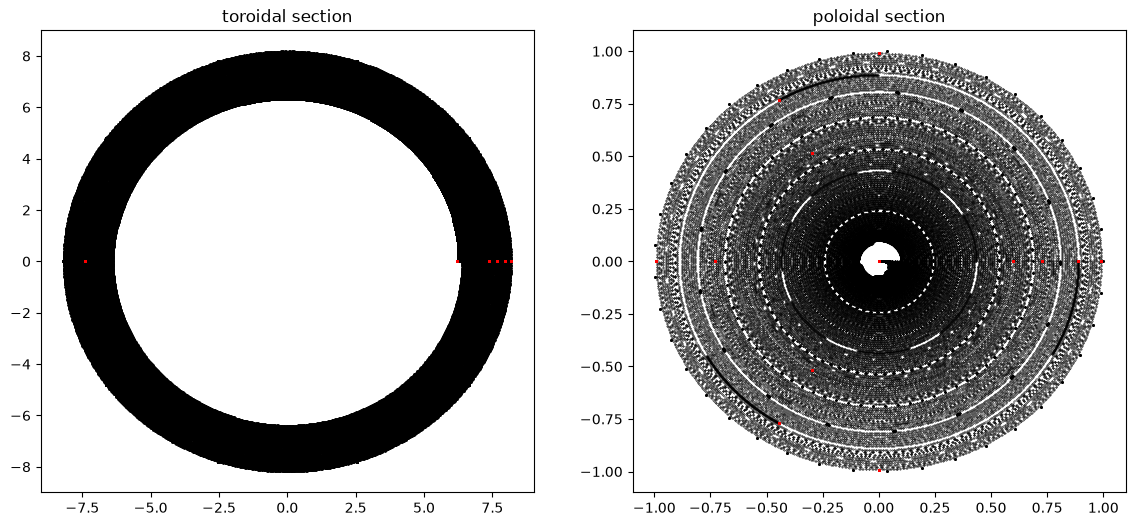

In [45]:
N = 1000 # Number of turns
Nr = 100 # Numero of radial points

fig, ax  = plt.subplots(1,2, figsize=(14,6))
x1 = np.linspace(0, 1, Nr)

turns = 2*np.pi*np.arange(N)

R, TURNS = np.meshgrid(x1, turns)

TH = TURNS / qITER(x1)[np.newaxis, :]
Z = TURNS * qITER(x1)[np.newaxis, :]

ax[0].scatter((params["R0"]+R*params["a"])*np.cos(Z), (params["R0"]+R*params["a"])*np.sin(Z), c='black', s=1)
ax[0].set_title('toroidal section')

ax[1].scatter(R*np.cos(TH), R*np.sin(TH), c='black', s=0.1)
ax[1].set_title('poloidal section')

R, TURNS = np.meshgrid(list(r0.values()), turns)

TH = TURNS / np.array(list(resonances.values()))[np.newaxis, :]
Z = TURNS * np.array(list(resonances.values()))[np.newaxis,:]

#m_grid = np.broadcast_to(m[np.newaxis, :], np.shape(R))

ax[1].scatter(R*np.cos(TH), R*np.sin(TH), c='r', s=1 )

ax[0].scatter((params["R0"]+R*params["a"])*np.cos(Z), (params["R0"]+R*params["a"])*np.sin(Z), c='r', s=1)
